# Лабораторная работа 2. Логистическая и линейная регрессии

Цель эксперимента — сравнить sklearn и собственную реализацию на классификации переписчиков и оценке мощности волновой фермы. Все варианты оцениваются на одних и тех же объектах.

## Задачи и разбиение


**Avila** содержит десять признаков геометрии текстовых фрагментов латинской рукописи XII века. Классификация по переписчикам позволяет предварительно распределять фрагменты перед проверкой палеографом. Используется разбиение UCI. Номера страниц в признаках отсутствуют, поэтому результаты относятся к этому протоколу и одному манускрипту. [Источник и словарь признаков](https://doi.org/10.24432/C5K02X)

**Wave Energy Converters · Tasmania.** По координатам 16 преобразователей требуется оценить суммарную мощность фермы. Такой прогноз может ускорить отбор вариантов перед запуском гидродинамического симулятора. 16 индивидуальных мощностей исключены: их сумма практически равна целевой переменной. Разбиение учитывает группы конфигураций по координатам, округлённым до 10 м. Соседние конфигурации по разные стороны границы округления могут оказаться в разных частях. Данные охватывают один волновой сценарий. [Источник и схема данных](https://doi.org/10.24432/C5831S)

Обе задачи используют по три внутренних фолда. В каждом фолде масштабирование и модель подгоняются только по его обучающей части. Holdout одинаков для всех пяти работ и используется после выбора конфигураций.

In [1]:
# Загружаем фиксированные разбиения и общие функции эксперимента.
import pandas as pd
from IPython.display import Markdown, display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 2
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila — автор фрагмента,20867,10430,10437,10,Официальные train/test; 3 стратифицированных ф...
1,Tasmania — суммарная мощность (МВт),72000,5762,1438,32,Групповой holdout 20% групп; 3 групповых фолда...


,Avila — автор фрагмента
Точных совпадений векторов признаков между train/test,0


,Tasmania — суммарная мощность (МВт)
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Выбор метрик


**Avila.** Macro-F1 усредняет F1 по всем 12 классам, сохраняя вклад редких переписчиков. Balanced accuracy — средняя полнота по классам. Accuracy показывает долю верных ответов по всем фрагментам.

**Tasmania.** MAE в МВт показывает средний абсолютный промах. RMSE в тех же единицах сильнее учитывает большие ошибки. R² отражает долю объяснённой вариации относительно среднего отклика теста и может быть отрицательным.

Для проверки полезности моделей используется простой ориентир. Классификационный dummy всегда выбирает самый частый класс train, регрессионный — медиану train. Основные метрики для выбора конфигурации — macro-F1 (выше) и MAE (ниже).

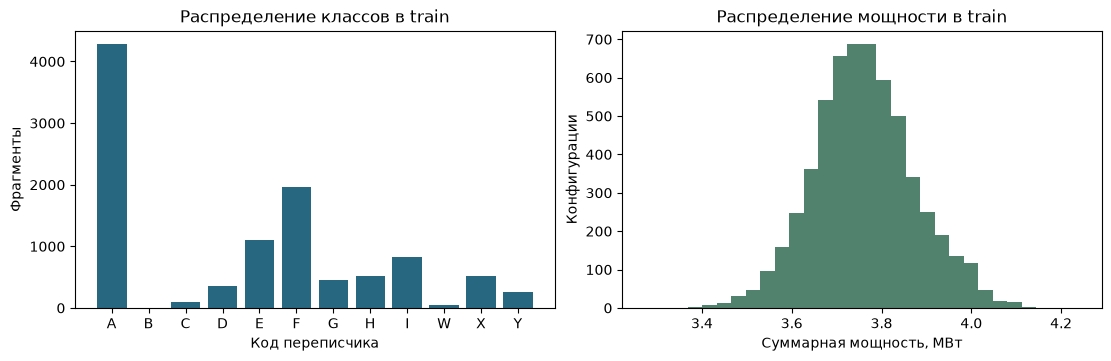

In [2]:
# Изучаем дисбаланс классов и масштаб мощности на обучающих данных.
plot_training(tasks)

## Библиотечный бейзлайн

Для классификации используется LogisticRegression с мультиномиальной функцией потерь, L2-штрафом и C=1. Для регрессии LinearRegression минимизирует сумму квадратов ошибок с учётом свободного члена.

## Гипотезы и кросс-валидация

Для Avila сравниваются веса, обратно пропорциональные частоте класса, более сильная регуляризация и квадратичные признаки. Веса могут повысить полноту редких классов, а произведения признаков позволяют представить нелинейную границу в исходном пространстве. Для Tasmania проверяются геометрические признаки, Ridge и квадратичные взаимодействия, которые могут описать зависимость мощности от совместного расположения преобразователей.

В сетку включён бейзлайн. При равенстве средних метрик приоритет получает первая конфигурация. В таблицах приведены оценки каждого фолда и стандартное отклонение между фолдами.

In [3]:
# Проверяем гипотезы на трёх внутренних фолдах и фиксируем победителей.
selections = select_candidates(LAB, tasks)
for task in tasks:
    display(Markdown(f"**{task.title} · {primary_metric(task)}**"))
    display(selections[task.key][2].round(5))

**Avila — автор фрагмента · macro_f1**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.40776,0.02168,0.38641,0.40711,0.42975,False
1,Взвешивание редких классов,raw,"{""class_weight"": ""balanced""}",0.43066,0.00788,0.43525,0.42156,0.43516,False
2,Стандартизация и C=0.3,standard,"{""C"": 0.3}",0.34324,0.04984,0.29754,0.39639,0.33580,False
3,Квадратичные признаки и C=0.3,polynomial,"{""C"": 0.3}",0.57109,0.02057,0.54772,0.57904,0.58649,False
4,Квадратичные признаки и веса классов,polynomial,"{""C"": 0.3, ""class_weight"": ""balanced""}",0.57747,0.01708,0.55835,0.59121,0.58284,True


**Tasmania — суммарная мощность (МВт) · mae_mw**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.08153,0.00072,0.08227,0.08150,0.08083,False
1,Геометрия,geometry,{},0.05999,0.00023,0.05983,0.06025,0.05989,False
2,Геометрия и Ridge,geometry_standard,"{""alpha"": 10.0}",0.06048,0.00028,0.06054,0.06073,0.06018,False
3,Квадратичные признаки координат и Ridge,polynomial,"{""alpha"": 10.0}",0.04935,0.00076,0.04861,0.05012,0.04932,True
4,Квадратичные признаки геометрии и Ridge,geometry_polynomial,"{""alpha"": 10.0}",0.05170,0.00083,0.05105,0.05264,0.05142,False


## Оценка sklearn на отложенной выборке

Переобучаем бейзлайн и победителя CV на всём train. В итоговом сравнении сохраняем фактический результат даже при снижении качества на holdout.

In [4]:
# Получаем holdout-метрики и сохраняем прогнозы для анализа ошибок.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    display(Markdown(f"**{task.title}**"))
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,1.24710,0.00253,0.39651,0.39430,0.56146
2,sklearn tuned,Квадратичные признаки и веса классов,0.79664,0.03070,0.58688,0.72814,0.56721


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.00930,0.00057,0.08134,0.10510,0.12379
2,sklearn tuned,Квадратичные признаки координат и Ridge,0.28223,0.01984,0.04799,0.06213,0.69378


## Собственная реализация

SoftmaxRegression минимизирует среднюю взвешенную cross-entropy со штрафом L2 для коэффициентов. В коде явно вычисляются softmax, устойчивый log-sum-exp и аналитический градиент. L-BFGS из SciPy обновляет вектор параметров как универсальный оптимизатор. LinearLeastSquares центрирует матрицу и отклик, решает МНК и восстанавливает свободный член. Для Ridge добавляются строки с корнем из alpha на диагонали, поэтому свободный член остаётся без штрафа.

Параметры и преобразования переносятся из библиотечного бейзлайна и лучшей библиотечной конфигурации соответственно. Повторного подбора по holdout нет. [Код оценивателей](labkit/models.py)

In [5]:
# Сопоставляем две собственные версии с эквивалентными конфигурациями sklearn.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    display(Markdown(f"**{task.title}**"))
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,1.24710,0.00253,0.39651,0.39430,0.56146
2,sklearn tuned,Квадратичные признаки и веса классов,0.79664,0.03070,0.58688,0.72814,0.56721
3,own baseline,Бейзлайн,9.18676,0.00499,0.39656,0.39425,0.56137
4,own tuned,Квадратичные признаки и веса классов,3.88788,0.02582,0.58776,0.73014,0.56760


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.00930,0.00057,0.08134,0.10510,0.12379
2,sklearn tuned,Квадратичные признаки координат и Ridge,0.28223,0.01984,0.04799,0.06213,0.69378
3,own baseline,Бейзлайн,0.01078,0.00042,0.08134,0.10510,0.12379
4,own tuned,Квадратичные признаки координат и Ridge,0.59306,0.01690,0.04799,0.06213,0.69378


## Диагностика ошибок

Матрица ошибок нормирована по истинному классу. Точки на графике мощности сравниваются с диагональю идеального прогноза. Обе визуализации относятся к варианту sklearn, выбранному по CV.

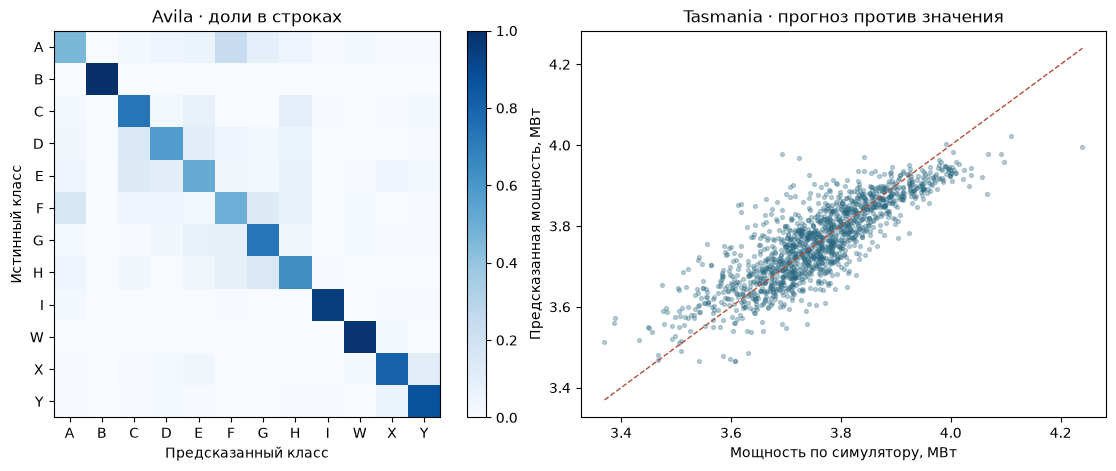

In [6]:
# Визуализируем ошибки классификации и отклонения мощности на holdout.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Формируем вывод из измеренных метрик и экспортируем входные данные для сводки.
display(Markdown(comparison_text(tasks, results, selections)))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

**Avila — автор фрагмента.** По CV выбран вариант «Квадратичные признаки и веса классов» (macro-F1 0.5775, бейзлайн 0.4078). На holdout macro-F1 sklearn улучшился относительно бейзлайна: 0.3965 → 0.5869. Собственная реализация: 0.3966 → 0.5878. Разница собственной модели и sklearn macro-F1: +0.0001 в бейзлайне, +0.0009 после настройки.

**Tasmania — суммарная мощность (МВт).** По CV выбран вариант «Квадратичные признаки координат и Ridge» (MAE 0.0494 МВт, бейзлайн 0.0815 МВт). На holdout MAE sklearn улучшился относительно бейзлайна: 0.0813 → 0.0480 МВт. Собственная реализация: 0.0813 → 0.0480 МВт. Разница собственной модели и sklearn MAE: +0.0000 МВт в бейзлайне, +0.0000 МВт после настройки.

Метрики сохранены в results/lab_02.csv
